In [8]:
import sys, os, importlib, tqdm
import pickle

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import netCDF4, h5py, scipy

In [30]:
import ASF; importlib.reload(ASF)
#scroller = ASF.TrackScroller('ICESat_search', buffer)
#scroller.search(delta=1, offset=43200, max_results=100)
#pickle.dump(scroller, open('ICESat_ASF_Search_260824.pickle', 'wb'))

In [3]:
#buffer.apply(lambda x: datetime.datetime.fromtimestamp(x['timestamp']), axis=-1)
#buffer = pd.concat(buffer, axis=0)
#buffer

scroller = pickle.load(open('ICESat_ASF_Search_260821.pickle','rb'))

In [23]:
buffer = pickle.load(open('ICESat_ASF_Feed_260821.pickle','rb'))
lop = 0
offset = 1
for i in tqdm.tqdm(range(1, len(buffer))):
    diff = buffer.iloc[i] - buffer.iloc[i - 1]
    if (diff[['lat','lon']].values**2).sum()**0.5 > 1:
        buffer.iloc[lop:i, buffer.columns.get_loc('timestamp')] -= offset # edit timestamp to distinguish track
        lop = i
        offset += 1

100%|███████████████████████████████████████████████████████████████████████| 2547632/2547632 [07:26<00:00, 5706.25it/s]


In [25]:
pickle.dump(buffer, open('ICESat_ASF_Feed_260824.pickle', 'wb'))

In [30]:
import data_cryos; importlib.reload(data_cryos)

#data_cryos.Compile_ICESat_Tracks()
buffer = []
dtl = [el.split('.')[0] for el in os.listdir('/mnt/d/ICESat1_data_060222_080321/NSIDC0393_GLAS_SI_Freeboard_v01/daily')]
for dt in dtl: # @ 250m sample rate - retrieve coarse 5000m interval for image search
    print('processing', dt)
    buffer.append(data_cryos.ICESat_Tracks_loc(dt, sr=20))
buffer = pd.concat(buffer, axis=0)

processing 20030220
processing 20030221
processing 20030222
processing 20030223
processing 20030224
processing 20030225
processing 20030226
processing 20030227
processing 20030228
processing 20030301
processing 20030302
processing 20030303
processing 20030304
processing 20030305
processing 20030306
processing 20030307
processing 20030308
processing 20030309
processing 20030310
processing 20030311
processing 20030312
processing 20030313
processing 20030314
processing 20030315
processing 20030316
processing 20030317
processing 20030318
processing 20030319
processing 20030320
processing 20031004
processing 20031005
processing 20031006
processing 20031007
processing 20031008
processing 20031009
processing 20031010
processing 20031011
processing 20031012
processing 20031013
processing 20031014
processing 20031015
processing 20031016
processing 20031017
processing 20031018
processing 20031019
processing 20031020
processing 20031021
processing 20031022
processing 20031023
processing 20031024


OSError: Can't synchronously read data (addr overflow, addr = 44935344, size = 2616, eoa = 44933296)

In [42]:
#pd.concat(buffer, axis=0)
import pickle
pickle.dump(buffer, open('ICESat_ASF_Feed_260821.pickle', 'wb'))

In [77]:
fn_ = "/mnt/c/Users/user/NSIDC0393_GLAS_SI_Freeboard_v01/glas_seaice_vectors/laser3e/laser3e0001002.txt"
icesat_df = pd.read_csv(fn_, sep=r"\s+", skiprows=22)
metadata = {}
for line in open(fn_, 'r'):
    if line.startswith("Latitude"): break
    if ": " not in line: continue
    key, value = (x.strip() for x in line.split(":", 1))
    metadata[key] = value
t = datetime.datetime(int(metadata['Year']), int(metadata['Month']), int(metadata['Day']), int(metadata['Hour']), int(metadata['Minute'])).timestamp()
icesat_df['timestamp'] = t
icesat_df

,Latitude,Longitude,Freeboard,Thickness,timestamp
0,71.890843,342.809108,0.563419,2.639533,1.141025e+09
1,71.892356,342.807873,0.499867,2.041737,1.141025e+09
2,71.893868,342.806636,0.526563,2.292931,1.141025e+09
3,71.895380,342.805399,0.445532,1.530707,1.141025e+09
4,71.896892,342.804163,0.492799,1.975423,1.141025e+09
...,...,...,...,...,...
16297,69.603393,183.334511,0.626331,4.034127,1.141025e+09
16298,69.601854,183.333580,0.549129,3.307864,1.141025e+09
16299,69.600312,183.332661,0.550121,3.317212,1.141025e+09
16300,69.598770,183.331750,0.345808,1.646892,1.141025e+09


<KeysViewHDF5 ['SI_12km_NH_18H_ASC', 'SI_12km_NH_18H_DAY', 'SI_12km_NH_18H_DSC', 'SI_12km_NH_18V_ASC', 'SI_12km_NH_18V_DAY', 'SI_12km_NH_18V_DSC', 'SI_12km_NH_23H_ASC', 'SI_12km_NH_23H_DAY', 'SI_12km_NH_23H_DSC', 'SI_12km_NH_23V_ASC', 'SI_12km_NH_23V_DAY', 'SI_12km_NH_23V_DSC', 'SI_12km_NH_36H_ASC', 'SI_12km_NH_36H_DAY', 'SI_12km_NH_36H_DSC', 'SI_12km_NH_36V_ASC', 'SI_12km_NH_36V_DAY', 'SI_12km_NH_36V_DSC', 'SI_12km_NH_89H_ASC', 'SI_12km_NH_89H_DAY', 'SI_12km_NH_89H_DSC', 'SI_12km_NH_89V_ASC', 'SI_12km_NH_89V_DAY', 'SI_12km_NH_89V_DSC', 'SI_12km_NH_ICECON_ASC', 'SI_12km_NH_ICECON_DAY', 'SI_12km_NH_ICECON_DSC', 'SI_12km_NH_ICEDIFF_ASC', 'SI_12km_NH_ICEDIFF_DAY', 'SI_12km_NH_ICEDIFF_DSC', 'SI_12km_NH_SNOWDEPTH_5DAY']>


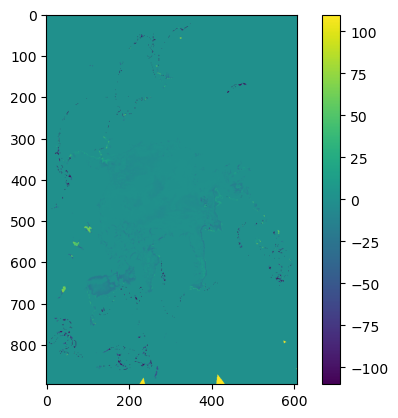

In [9]:
amsr_h5f = h5py.File('/mnt/d/AMSR_data_060516_110512/AMSR_UE_L3_SeaIce12km_B04_20101210.he5')
print(amsr_h5f['HDFEOS']['GRIDS']['NpPolarGrid12km']['Data Fields'].keys())
#amsr_h5f.close()
#plt.imshow(amsr_h5f['multiyear_mask'][:])
plt.imshow(amsr_h5f['HDFEOS']['GRIDS']['NpPolarGrid12km']['Data Fields']['SI_12km_NH_ICEDIFF_DAY'][:]); plt.colorbar()
amsr_h5f.close()

Text(0.5, 1.0, 'CryoSat2 2010.12.10 Sea Ice Thickness Gridded')

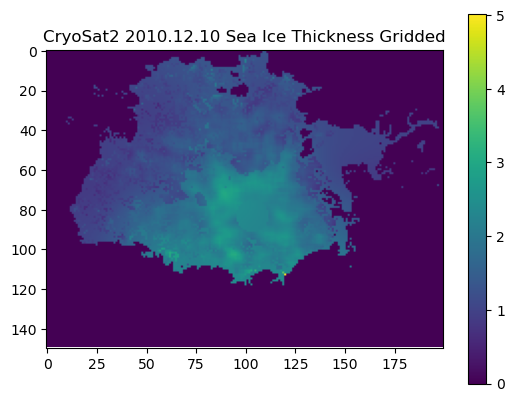

In [54]:
cs2_prod = netCDF4.Dataset('/mnt/d/CryoSat2_data_100920_110512/RDEFT4_20101210.nc')
cs2_sit = cs2_prod.variables['sea_ice_thickness'][:]
cs2_sit[cs2_sit == -9999.0] = 0
plt.imshow(cs2_sit[150:300, 50:250]); plt.colorbar(); plt.title('CryoSat2 2010.12.10 Sea Ice Thickness Gridded')
#cs2_prod.close(); plt.show()

In [20]:
import util_collector; importlib.reload(util_collector)
try: print(entries.shape)
except:
    grid_collector = util_collector.Dataset(fn='em_gridlook_260807.hdf5')
    entries = grid_collector.read(np.arange(grid_collector.h5f.attrs['w_ind']))
    cells_per_m = grid_collector.h5f.attrs['cells_per_m']
    grid_collector.close()
T_surf    = torch.as_tensor(entries['T'][:,0])
S_surf    = torch.as_tensor(entries['S'][:,0])
r_surf    = torch.as_tensor(entries['rho'][:,0])
th = (torch.as_tensor(entries['S']) != 35).cumsum(dim=-1).amax(dim=-1, keepdim=False) / cells_per_m
vals = [T_surf, S_surf, r_surf, th]
varn = ['Surface Temperature (C)','Surface Salinity (g/kg)','Surface Density (g/cm3)','Thickness(m)']

scatter   = torch.as_tensor(entries['rf'])
C4 = scatter[:,:,None] * scatter[:,None,:].conj()

In [21]:
medians = [val.median().item() for val in vals]; medians[-1] = th.unique()[1].item()
midpoint_masks = torch.stack([vals[i] == medians[i] for i in range(len(vals))], dim=-1).to(torch.bool)

In [22]:
Cmask = np.triu(np.ones((4,4)), k=1).astype(bool)
Clabel = 'C' + np.arange(1,5)[None,:].astype(str) + np.arange(1,5)[:,None].astype(str)
Clabel = Clabel[Cmask]

Surface Temperature (C) : -10.0
Surface Salinity (g/kg) : 6.0
Surface Density (g/cm3) : 0.75
Thickness(m) : 0.8999999761581421


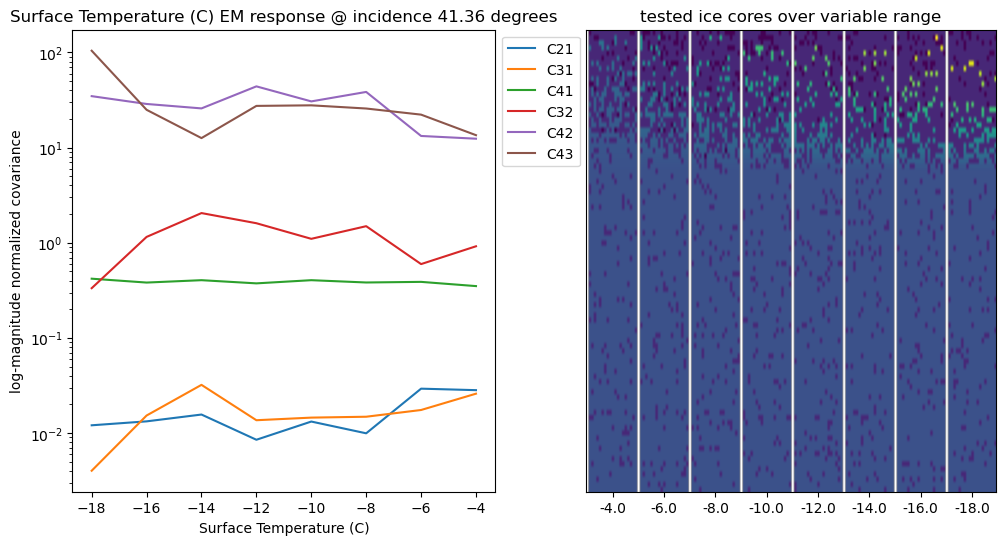

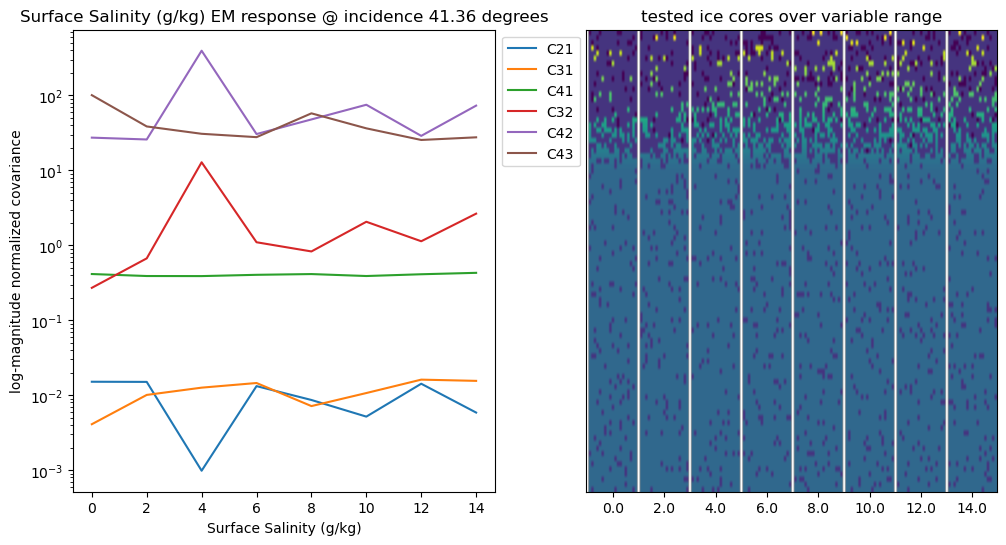

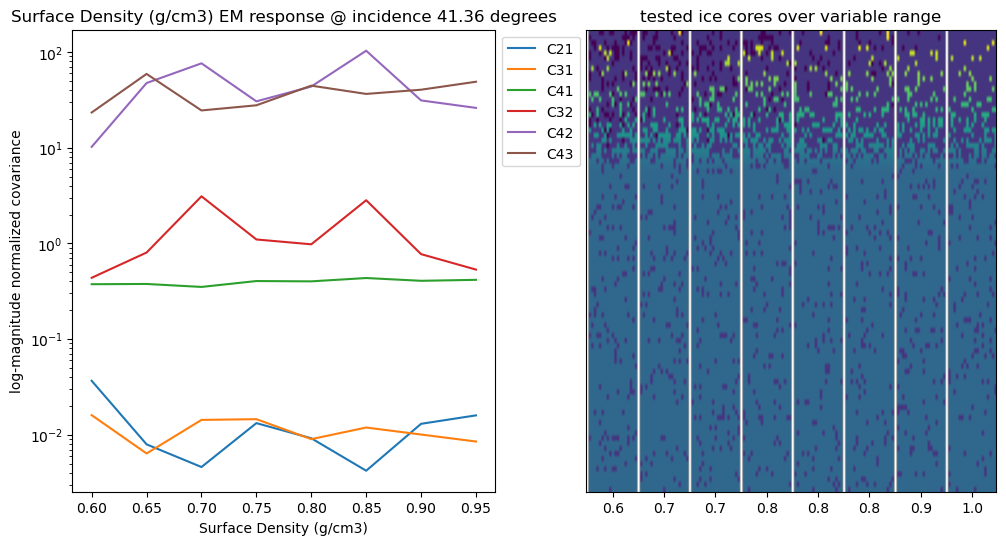

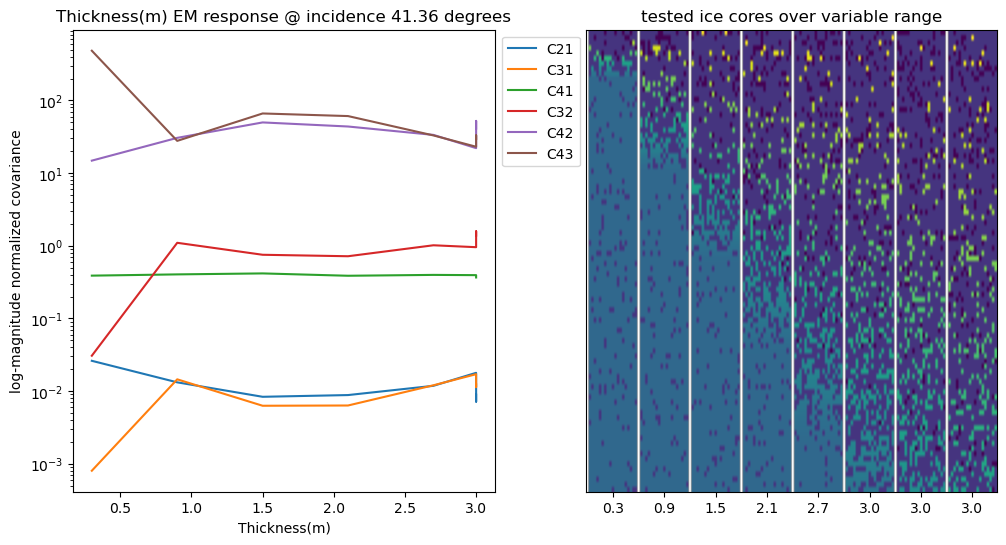

In [23]:
[print(varn[i],':',medians[i]) for i in range(len(medians))]
for index in range(4):
    
    look = midpoint_masks.clone(); look[:,index] = True
    look = look.prod(dim=-1).to(torch.bool)
    Clook = (C4[look] / C4[look].diagonal(0,1,2)[...,None].abs())[:,Cmask]
    plt.figure(figsize=(12,6))
    #for i in range(Clook.shape[-1]):
    #    plt.subplot(1,Clook.shape[-1],i+1)
    #    plt.plot(vals[index][look], C4.flatten(1)[look, i].abs())#
    plt.subplot(1,2,1)
    plt.title(f'{varn[index]} EM response @ incidence 41.36 degrees')
    plt.plot(vals[index][look], Clook.abs()); plt.yscale('log')
    plt.xlabel(varn[index])
    plt.ylabel('log-magnitude normalized covariance')
    plt.legend(Clabel, bbox_to_anchor=(1.0, 1.0))
    plt.subplot(1,2,2)
    test_n = look.sum().item()
    imv = entries['lt'][look].reshape(-1, 22, 77, 92)[:,1:-1,1,1:-1].reshape(-1, 90).T
    imv[..., np.arange(imv.shape[-1]) % (imv.shape[-1]/test_n) == 0] = np.nan
    imv[imv == -1] = -30
    plt.imshow(imv, aspect=2); plt.yticks([])
    plt.xticks(np.linspace(0.5*imv.shape[-1]/test_n, imv.shape[-1]-(0.5*imv.shape[-1]/test_n), test_n), (vals[index][look]).round(decimals=1).numpy().astype(str))
    plt.title('tested ice cores over variable range')
    plt.show()



In [388]:
C4.diagonal(0,1,2)[...,None].abs()

torch.Size([4108, 4, 1])

In [67]:
import PyPreprocess_Single; importlib.reload(PyPreprocess_Single)
import script_CoreExplorer; importlib.reload(script_CoreExplorer)
import util_collector; importlib.reload(util_collector)
import brack2bing; importlib.reload(brack2bing)
import os, math

try: print(slc_ds.slc.shape)
except:
    slc_dir = '/mnt/d/ALOS1_Ellesmere_260730Look/'
    slc_fn = [el for el in os.listdir(slc_dir) if el[-4:] == '.zip'][1]
    cache_dir = slc_dir + slc_fn.split('-')[0] + '_cache'
    slc_ds = PyPreprocess_Single.Dataset_SNAPbase(src_fn=slc_dir + slc_fn,
                                                  cache_dir=cache_dir, read_nc=True, alos1_deskew=True)
    #slc_ds = PyPreprocess_Single.Dataset_SNAPbase.load_cache(cache_dir=cache_dir)
slc, ia = slc_ds.slc[:,:1000], slc_ds.ia[:1000]

located cache at /mnt/d/ALOS1_Ellesmere_260730Look/ALPSRP259791620_cache
extracting parameters...
retrieved metadata.
retrieved SLC complex (B,H,W).
rescaling auxiliary data...
converted incidence angle from degrees to radians.
all parameters extracted.
dataset loaded.


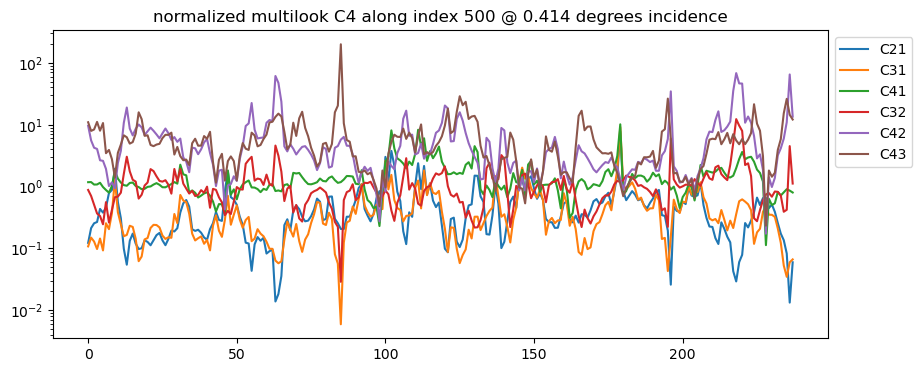

In [424]:
#Cmask = np.triu(np.ones((4,4))).astype(bool)
#Clabel = ('C' + np.arange(1,5)[None,:].astype(str) + np.arange(1,5)[:,None].astype(str))[Cmask]
Cmask = np.triu(np.ones((4,4)), k=1).astype(bool)
Clabel = 'C' + np.arange(1,5)[None,:].astype(str) + np.arange(1,5)[:,None].astype(str)
Clabel = Clabel[Cmask]

c4look = torch.squeeze((F.avg_pool2d(torch.as_tensor(slc.real[:,495:506,:])[None,], 11, stride=1)
          + 1j * F.avg_pool2d(torch.as_tensor(slc.imag[:,495:506,:])[None,], 11, stride=1))[0,...]).permute(1,0)

c4look = (c4look[:,None,:] * c4look[:,:,None].conj())
c4look = c4look / c4look.diagonal(0,1,2).abs()[...,None]
c4look = c4look[:,Cmask]

plt.figure(figsize=(10,4))
plt.plot(c4look.abs()[1000:]); plt.yscale('log')
plt.title(f'normalized multilook C4 along index 500 @ {ia[:,500].mean().round(3).astype(str)} degrees incidence')
plt.legend(Clabel, bbox_to_anchor=(1.0, 1.0))
plt.show()

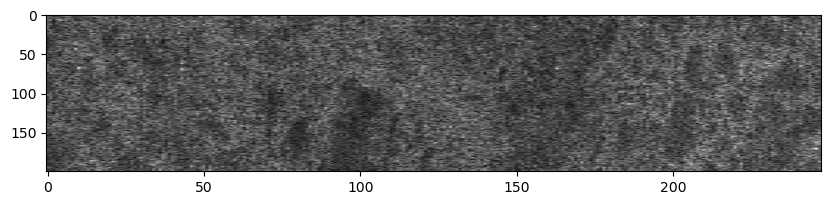

In [421]:
plt.figure(figsize=(10,4))
plt.imshow((np.abs(slc[3,400:600,1000:])**0.5), cmap='gray', aspect=0.25)

In [395]:
slc.real.shape

(4, 1000, 1248)

In [385]:
c4look.diagonal(0,1,2).abs()[:,None].shape

torch.Size([990, 1, 4])

In [377]:
ia[:,500].mean().item()

0.413846492767334